# Tutorial 3: Primitives and Mesh Generation

You do not always have a mesh file. This tutorial loads ready-made example
meshes from `physicsnemo.mesh.primitives`, and generates simulation meshes from a
description of their shape. You can even differentiate a generated mesh with
respect to the parameters of its shape.

**What You Will Build:** example meshes from every family, and simulation meshes
generated from a closed boundary, an implicit shape, and a 3D grid of values.

You will learn:

- Which example meshes `physicsnemo.mesh.primitives` provides, and how to load one
- How to choose between `fill_interior`, `mesh_implicit_domain`, and
  `marching_cubes`, and how to use each of them
- How to compute gradients with respect to shape parameters with
  `refit_mesh_to_implicit`

Prerequisites: [Tutorial 1: Getting Started](tutorial_1_getting_started.ipynb)
and [Tutorial 2: Loading, Converting, and Saving Meshes](tutorial_2_io_interop.ipynb).
The notebook runs on a CPU and uses a GPU when one is present.

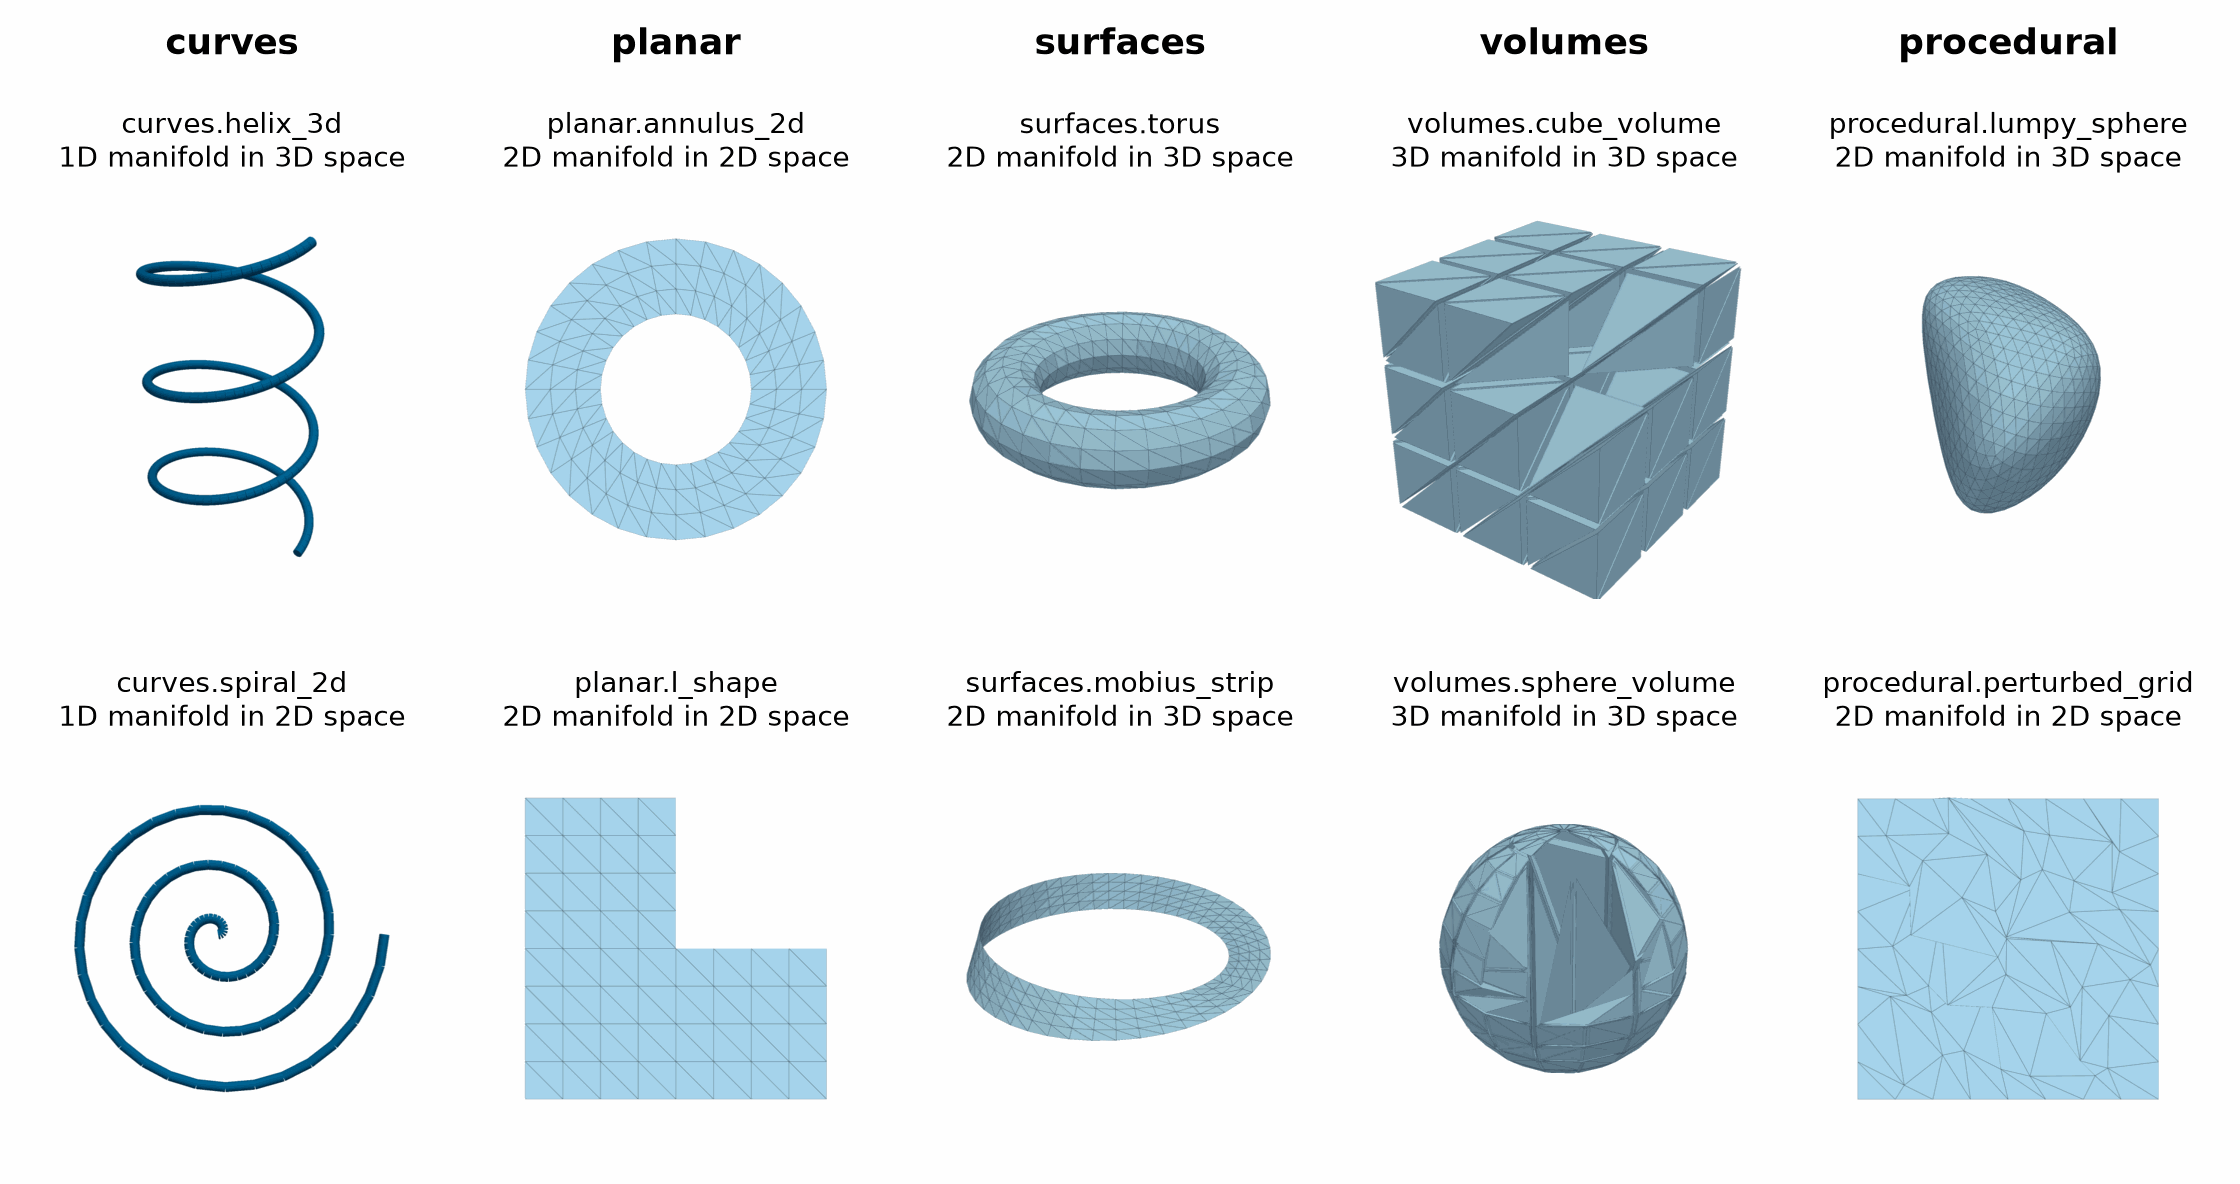

In [1]:
from IPython.display import Image

Image(filename="../../../docs/img/mesh/primitives_gallery.png", width=800)

In [2]:
import math
import pkgutil

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
import torch

from physicsnemo.mesh import Mesh, primitives
from physicsnemo.mesh.primitives import (
    basic,
    curves,
    planar,
    procedural,
    pyvista_datasets,
    surfaces,
    volumes,
)

pv.set_jupyter_backend("static")
pv.global_theme.window_size = [700, 450]

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
print(f"device: {device}")

device: cuda


## 1. Example Meshes in `physicsnemo.mesh.primitives`

Small, known meshes help you test code, try an idea, or check a result against
a closed-form answer, such as the area of a sphere. `physicsnemo.mesh.primitives`
builds them at run time, so they need no data files. The figure at the top shows
two meshes from each of five families. The table lists all seven, with the
dimensions as `[manifold, spatial]`:

| Family | Dimensions | Contents |
|--------|------------|----------|
| `basic` | `[0-3, 2-3]` | One to three points, edges, triangles, or tetrahedra, for unit tests |
| `curves` | `[1, 1]`, `[1, 2]`, `[1, 3]` | Lines, arcs, circles, spirals, a helix, a trefoil knot |
| `planar` | `[2, 2]` | Triangulated squares, rectangles, disks, an annulus, an L shape |
| `surfaces` | `[2, 3]` | Spheres, cylinders, a cone, a disk, a plane, a torus, a Mobius strip, Platonic solids |
| `volumes` | `[3, 3]` | Tetrahedral meshes of a cube, a sphere, a cylinder, and a tetrahedron |
| `procedural` | various | Shapes with seeded random noise: lumpy spheres and balls, perturbed grids |
| `pyvista_datasets` | `[2, 3]`, `[3, 3]` | PyVista's example meshes, such as the Stanford bunny |

Each family is a Python package with one module for each mesh:

In [3]:
for family in [basic, curves, planar, surfaces, volumes, procedural, pyvista_datasets]:
    names = [info.name for info in pkgutil.iter_modules(family.__path__)]
    print(f"{family.__name__.split('.')[-1]:17s} {', '.join(names)}")

basic             single_edge_2d, single_edge_3d, single_point_2d, single_point_3d, single_tetrahedron, single_triangle_2d, single_triangle_3d, three_edges_2d, three_edges_3d, three_points_2d, three_points_3d, two_tetrahedra, two_triangles_2d, two_triangles_3d
curves            circle_2d, circle_3d, circular_arc_2d, ellipse_2d, helix_3d, line_segment_1d, line_segments_1d, polyline_2d, spiral_2d, spline_3d, straight_line_2d, straight_line_3d, trefoil_knot_3d
planar            annulus_2d, circle_2d, equilateral_triangle, l_shape, rectangle, regular_polygon, structured_grid, unit_square
surfaces          cone, cube_surface, cylinder, cylinder_open, disk, hemisphere, icosahedron_surface, mobius_strip, octahedron_surface, plane, sphere_icosahedral, sphere_uv, tetrahedron_surface, torus
volumes           cube_volume, cylinder_volume, sphere_volume, tetrahedron_volume
procedural        lumpy_ball, lumpy_sphere, noise, noisy_mesh, perturbed_grid
pyvista_datasets  airplane, ant, bunny, cow, glo

The `procedural` family also has `noise`, which holds Perlin noise functions
rather than a mesh.

### Load a Primitive

Each mesh module has a `load` function that returns a `Mesh`. For most meshes,
keyword arguments set the size and the resolution, and `device` sets where the
tensors live. The `basic` meshes take only `device`, and
`procedural.noisy_mesh.load` takes a base mesh, a noise scale, and a seed.
Import the module, or reach it through `primitives`:

In [4]:
torus = surfaces.torus.load(major_radius=1.0, minor_radius=0.3, n_major=48, n_minor=24)
same_torus = primitives.surfaces.torus.load(
    major_radius=1.0, minor_radius=0.3, n_major=48, n_minor=24
)
print(torus)
print(f"same mesh: {torch.equal(torus.points, same_torus.points)}")

Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=1152, n_cells=2304)
same mesh: True


A primitive with a closed-form answer makes a quick test. The area of the torus
is $4 \pi^2 R r$, and the triangulated surface comes close to it:

In [5]:
exact_area = 4 * math.pi**2 * 1.0 * 0.3
print(f"mesh area:  {torus.cell_areas.sum():.4f}")
print(f"exact area: {exact_area:.4f}")

mesh area:  11.7887
exact area: 11.8435


The resolution arguments differ by mesh. For `sphere_icosahedral`, each level of
`subdivisions` splits every triangle into four. Pass `device` to build the mesh
directly on a GPU:

In [6]:
for level in range(5):
    sphere = surfaces.sphere_icosahedral.load(subdivisions=level, device=device)
    print(
        f"subdivisions={level}: {sphere.n_cells:5d} triangles, "
        f"area {sphere.cell_areas.sum():.4f} (exact {4 * math.pi:.4f}), "
        f"on {sphere.points.device}"
    )

subdivisions=0:    20 triangles, area 9.5745 (exact 12.5664), on cuda:0


subdivisions=1:    80 triangles, area 11.6659 (exact 12.5664), on cuda:0
subdivisions=2:   320 triangles, area 12.3291 (exact 12.5664), on cuda:0
subdivisions=3:  1280 triangles, area 12.5062 (exact 12.5664), on cuda:0
subdivisions=4:  5120 triangles, area 12.5513 (exact 12.5664), on cuda:0


### Procedural Meshes Are Seeded

The `procedural` meshes add noise to a base shape, which makes them good test
inputs for code that must handle irregular meshes. The same `seed` always gives
the same mesh, so a test that uses one is reproducible. `noisy_mesh` adds noise
to any mesh that you pass in:

In [7]:
lumpy_a = procedural.lumpy_sphere.load(noise_amplitude=0.3, seed=7)
lumpy_b = procedural.lumpy_sphere.load(noise_amplitude=0.3, seed=7)
lumpy_c = procedural.lumpy_sphere.load(noise_amplitude=0.3, seed=8)
print(f"same seed, same mesh:           {torch.equal(lumpy_a.points, lumpy_b.points)}")
print(
    f"different seed, different mesh: {not torch.equal(lumpy_a.points, lumpy_c.points)}"
)

noisy_square = procedural.noisy_mesh.load(
    planar.unit_square.load(subdivisions=3), noise_scale=0.02, seed=0
)
print(noisy_square)

same seed, same mesh:           True
different seed, different mesh: True
Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=81, n_cells=128)


### PyVista Datasets

The `pyvista_datasets` modules wrap PyVista's example meshes. PyVista downloads
some of them on first use, so they need internet access once. After that, they
load from PyVista's cache. Like `from_pyvista` (Tutorial 2), they split
non-simplex cells. The hexahedral beam below becomes a tetrahedral mesh:

In [8]:
beam = pyvista_datasets.hexbeam.load()
print(beam)

Mesh[n_manifold_dims=3, n_spatial_dims=3](n_points=99, n_cells=240, device=cpu)
    point_data: {VTKorigID: (), sample_point_scalars: ()}
    cell_data : {sample_cell_scalars: ()}


## 2. Choose a Mesh Generator

A simulation needs a mesh of its own domain, not a sphere or a torus. The library
has three generators, and each starts from a different description of the shape:

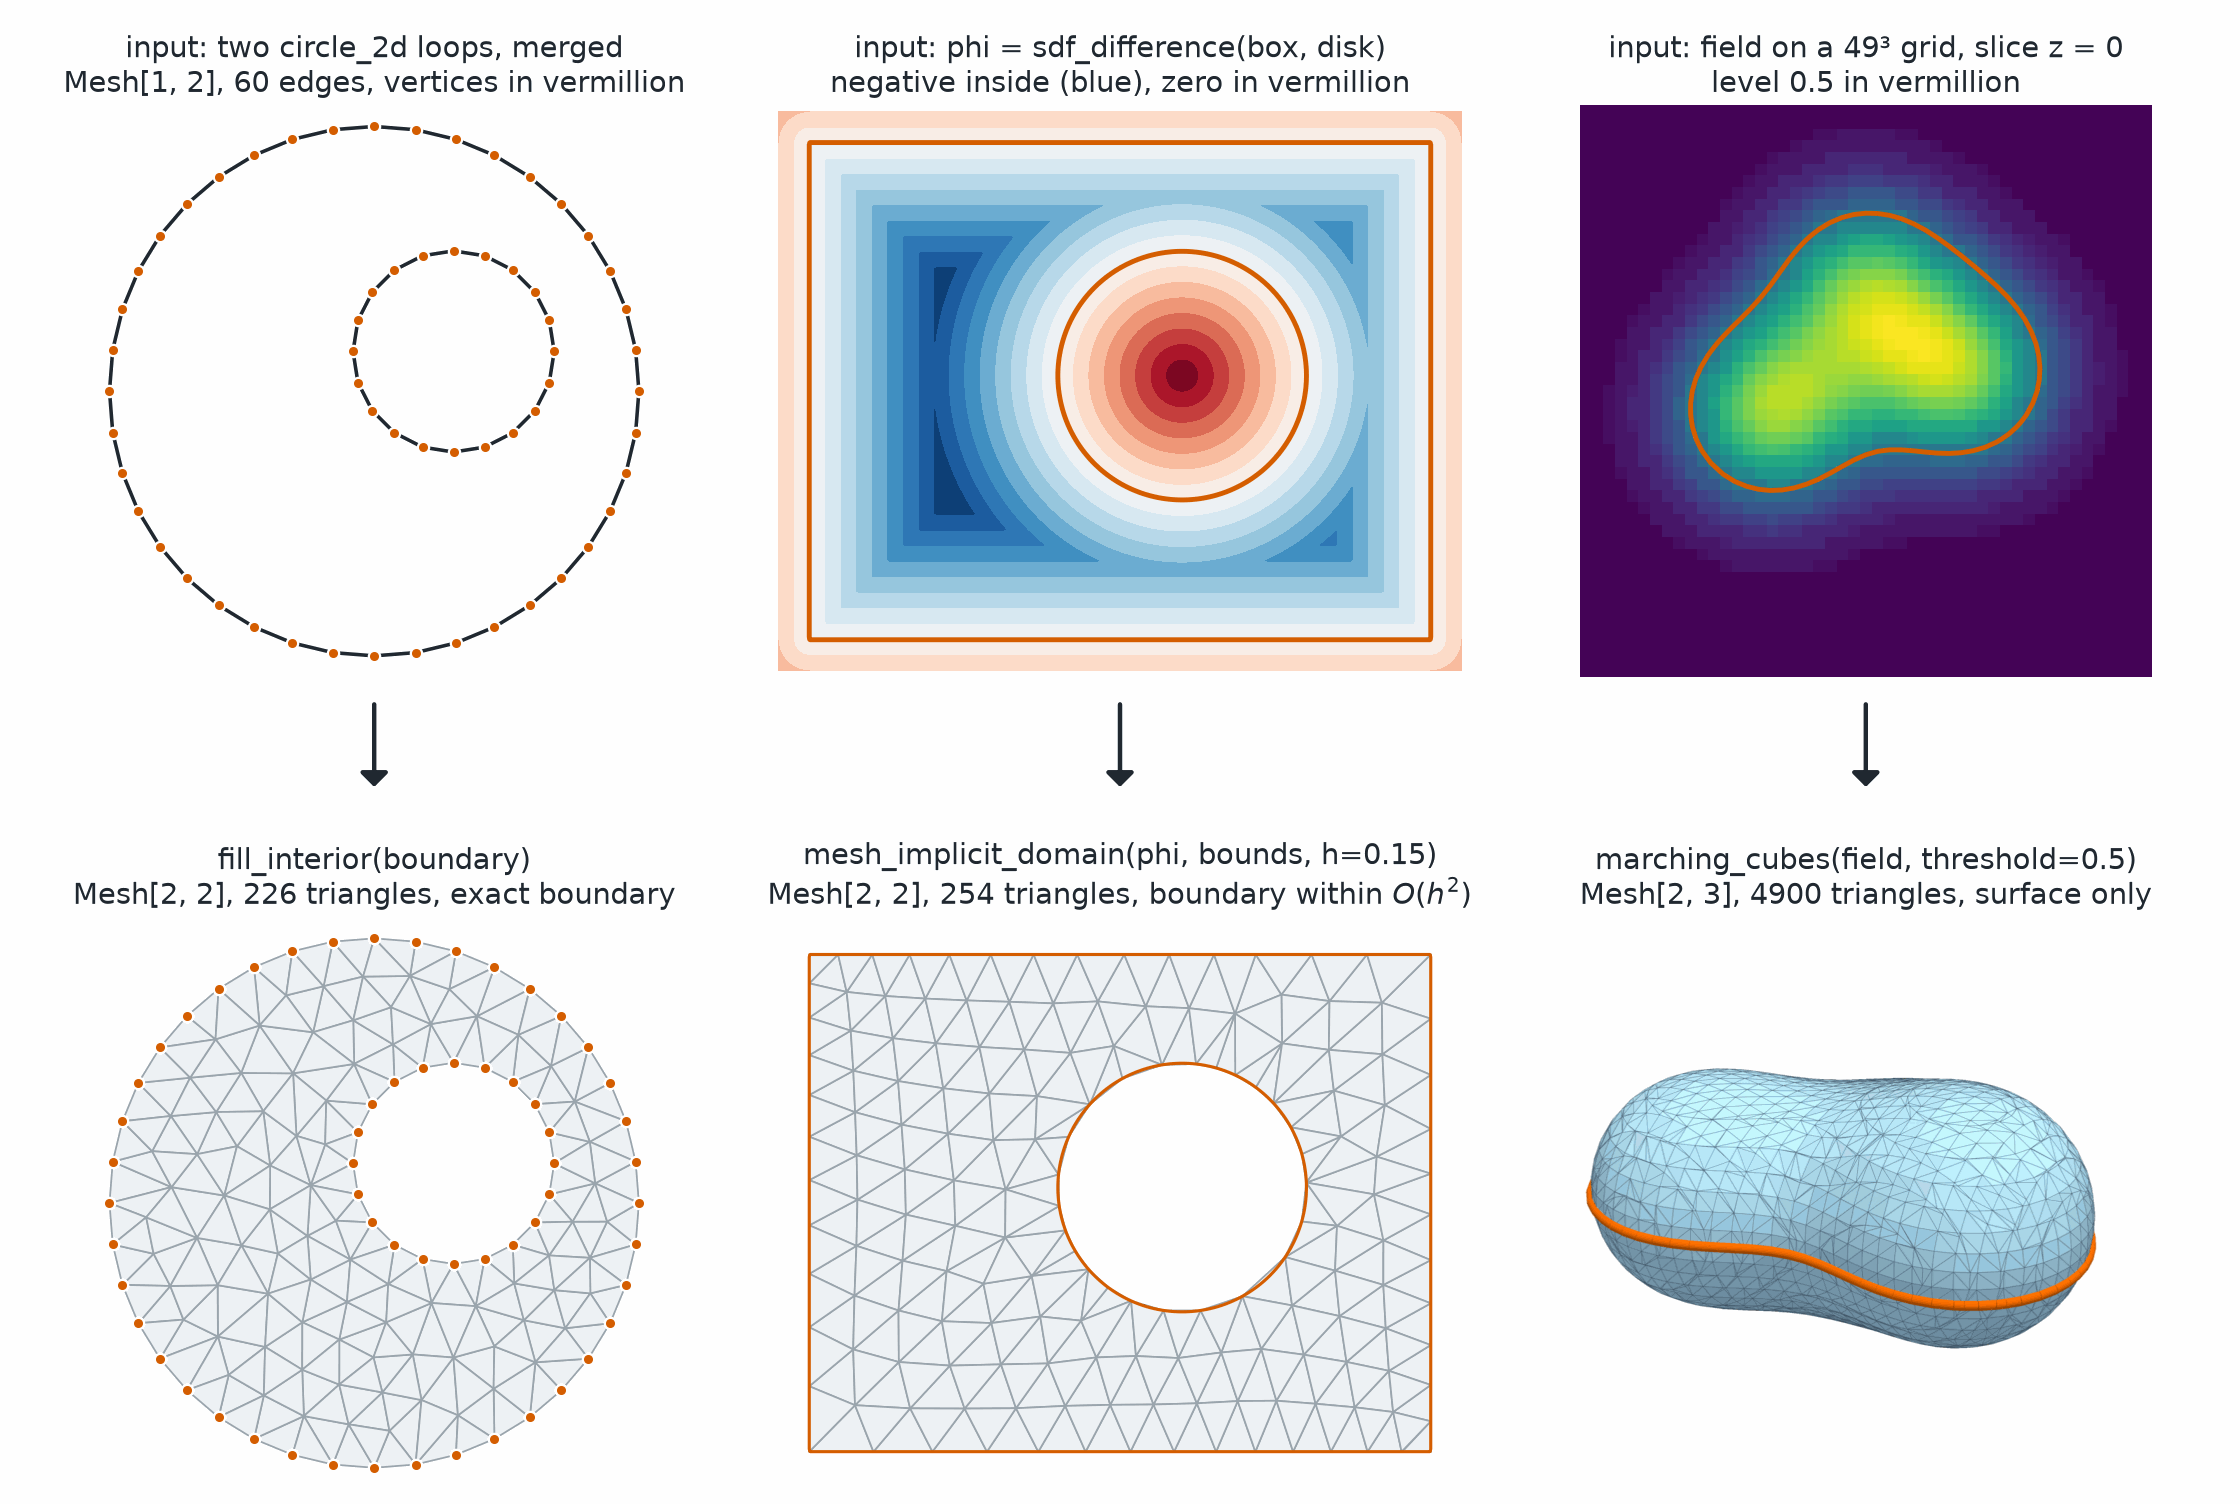

In [9]:
Image(filename="../../../docs/img/mesh/mesh_generators.png", width=800)

Choose by what you know about the shape:

| | `tessellation.fill_interior` | `generate.mesh_implicit_domain` | `generate.marching_cubes` |
|---|---|---|---|
| Input | Closed boundary mesh, `Mesh[1, 2]` | Implicit function: negative inside, positive outside | Scalar field on a 3D grid |
| Output | Triangles, `Mesh[2, 2]` | Simplices in any dimension d, `Mesh[d, d]` | Triangle surface, `Mesh[2, 3]` |
| Boundary | The input vertices, kept exactly | Vertices projected onto the zero level set | Interpolated from the grid |
| Cell quality | Guaranteed minimum angle (input corners >= 60 degrees) | Optimized, reported in diagnostics | Not controlled |
| Gradients | No | Yes, through `refit_mesh_to_implicit` | No |

`fill_interior` works in 2D today. For a 3D boundary, it raises
`NotImplementedError`.

## 3. Fill a Closed Boundary with `fill_interior`

When the boundary discretization is fixed, for example by a CAD export or by a
boundary condition that you must match vertex for vertex, fill it. `fill_interior`
takes the boundary as an edge mesh: one or more closed loops, in any order and
orientation. It finds out which loops are outer boundaries, which are holes, and
which are islands inside holes.

The boundary below has three loops: a gear, a star-shaped hole inside it, and a
small circular island inside the hole.

In [10]:
from physicsnemo.mesh.tessellation import fill_interior


def loop(curve, n, offset):
    """Sample ``curve`` at ``n`` angles and connect the samples into a closed loop."""
    t = torch.arange(n, dtype=torch.float64) / n * 2 * math.pi
    i = torch.arange(n)
    return curve(t), torch.stack([i, (i + 1) % n], dim=1) + offset


def gear(t):
    r = 1.0 + 0.13 * torch.tanh(4 * torch.sin(9 * t))
    return torch.stack([r * torch.cos(t), r * torch.sin(t)], dim=1)


def star(t):
    r = 0.42 * (1 + 0.3 * torch.cos(5 * t))
    return torch.stack([r * torch.cos(t), r * torch.sin(t)], dim=1)


def island(t):
    return torch.stack([0.1 * torch.cos(t), 0.1 * torch.sin(t)], dim=1)


loop_sizes = [240, 72, 16]
p1, e1 = loop(gear, loop_sizes[0], 0)
p2, e2 = loop(star, loop_sizes[1], 240)
p3, e3 = loop(island, loop_sizes[2], 312)
boundary = Mesh(points=torch.cat([p1, p2, p3]), cells=torch.cat([e1, e2, e3]))
print(boundary)

Mesh[n_manifold_dims=1, n_spatial_dims=2](n_points=328, n_cells=328)


`max_cell_size` bounds the area of each triangle. For a target edge length `h`,
pass the area of an equilateral triangle, $\sqrt{3} h^2 / 4$. `smooth_iterations`
moves the interior vertices to improve the cells, and never moves boundary
vertices. `provenance=True` records where each output vertex came from, as the
next section shows.

In [11]:
h = 0.045
filled = fill_interior(
    boundary,
    max_cell_size=math.sqrt(3) / 4 * h**2,
    smooth_iterations=3,
    provenance=True,
)
print(filled)

kept = torch.equal(filled.points[: boundary.n_points], boundary.points)
print(f"input vertices kept exactly, as the first rows of points: {kept}")

Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=2675, n_cells=4881)
    point_data: {boundary_marker: (), source_point: ()}
input vertices kept exactly, as the first rows of points: True


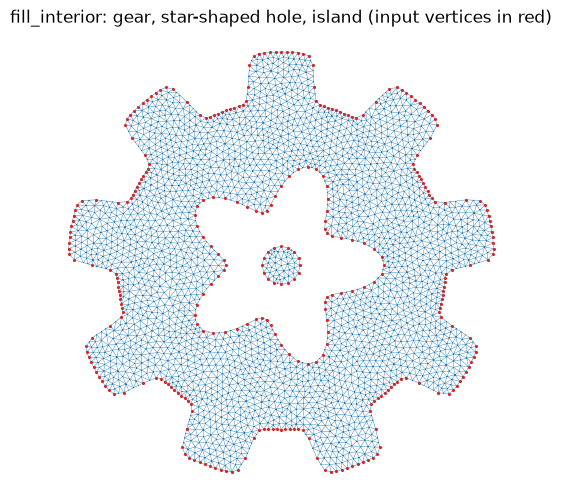

In [12]:
pts = filled.points.numpy()
bp = boundary.points.numpy()
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.triplot(pts[:, 0], pts[:, 1], filled.cells.numpy(), lw=0.3, color="C0")
ax.plot(bp[:, 0], bp[:, 1], ".", ms=2.5, color="C3")
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("fill_interior: gear, star-shaped hole, island (input vertices in red)")
plt.show()

### Carry Boundary Data to the Output with Provenance

Boundary conditions are often tagged on the input boundary. For example, this
loop is a wall, and that one is an inlet. With `provenance=True`, the output
`point_data` gets two fields:

- `boundary_marker` is 1 for vertices on the input boundary and 0 for interior
  vertices.
- `source_point` is the index of the input vertex that each output vertex came
  from, or -1 for a new vertex.

With `source_point`, a per-vertex tag of the input becomes a tag of the output.
Here, the tag is the loop that each input vertex belongs to:

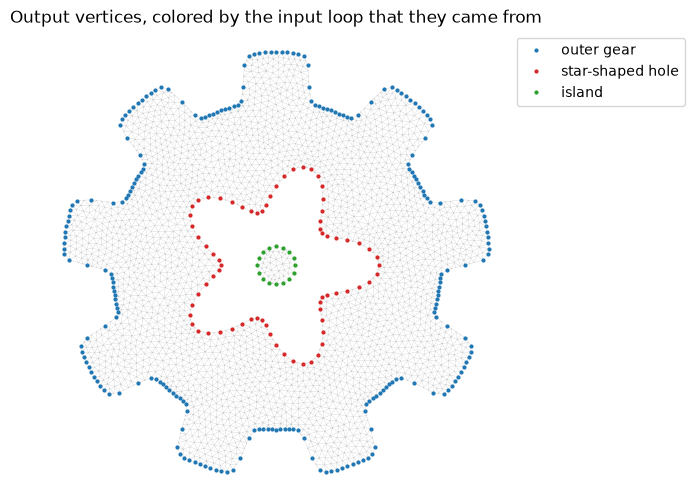

In [13]:
loop_id = torch.cat([torch.full((n,), k) for k, n in enumerate(loop_sizes)])

source = filled.point_data["source_point"]
output_loop = torch.full((filled.n_points,), -1)
output_loop[source >= 0] = loop_id[source[source >= 0]]

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.triplot(pts[:, 0], pts[:, 1], filled.cells.numpy(), lw=0.25, color="0.8")
for k, (name, color) in enumerate(
    [("outer gear", "C0"), ("star-shaped hole", "C3"), ("island", "C2")]
):
    selected = (output_loop == k).numpy()
    ax.plot(pts[selected, 0], pts[selected, 1], ".", ms=4, color=color, label=name)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("Output vertices, colored by the input loop that they came from")
plt.show()

Refinement can also insert new vertices on the boundary, between input vertices.
They have `boundary_marker == 1` and `source_point == -1`:

In [14]:
marker = filled.point_data["boundary_marker"]
print(f"input vertices:            {int((source >= 0).sum())}")
print(f"new vertices on boundary:  {int(((marker == 1) & (source < 0)).sum())}")
print(f"new interior vertices:     {int((marker == 0).sum())}")

input vertices:            328
new vertices on boundary:  139
new interior vertices:     2208


### The Minimum Angle Is a Guarantee

Thin triangles slow solvers down and make discrete derivatives inaccurate.
`fill_interior` uses Ruppert refinement, which guarantees that every triangle
has a minimum angle of at least `min_angle_degrees` (30 by default, 33 at most).
The guarantee needs input corners of at least about 60 degrees, where two
boundary segments meet. It holds at every resolution. The histograms show the
smallest angle of each triangle, computed by `quality_metrics`, at three edge
lengths:

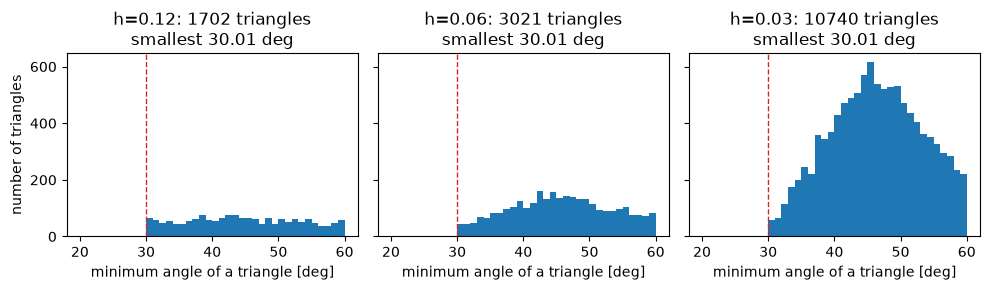

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, edge_length in zip(axes, [0.12, 0.06, 0.03]):
    mesh = fill_interior(boundary, max_cell_size=math.sqrt(3) / 4 * edge_length**2)
    min_angle = torch.rad2deg(mesh.quality_metrics["min_angle"]).numpy()
    ax.hist(min_angle, bins=np.linspace(20, 60, 41), color="C0")
    ax.axvline(30, color="C3", ls="--", lw=1)
    ax.set_title(
        f"h={edge_length}: {mesh.n_cells} triangles\nsmallest {min_angle.min():.2f} deg"
    )
    ax.set_xlabel("minimum angle of a triangle [deg]")
axes[0].set_ylabel("number of triangles")
fig.tight_layout()
plt.show()

A sharper input corner raises a `ValueError`, because refinement cannot then
meet the angle bound near the corner. The wedge below has a 20-degree tip. With
`min_angle_degrees=0.0`, `fill_interior` drops the angle bound and splits cells
only to meet `max_cell_size`:

In [16]:
tip = math.radians(20)
wedge = Mesh(
    points=torch.tensor(
        [[0.0, 0.0], [1.0, 0.0], [math.cos(tip), math.sin(tip)]], dtype=torch.float64
    ),
    cells=torch.tensor([[0, 1], [1, 2], [2, 0]]),
)
try:
    fill_interior(wedge, max_cell_size=0.005)
except ValueError as error:
    print(f"ValueError: {error}")

print(fill_interior(wedge, max_cell_size=0.005, min_angle_degrees=0.0))

ValueError: loop 0 has adjacent segments meeting at 20.0 degrees (vertex 0 at [0.0, 0.0]); the min-angle refinement guarantee requires input corners of at least ~60 degrees. Pass min_angle_degrees=0.0 for an unrefined constrained triangulation, or blunt the corner geometrically.
Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=45, n_cells=57)


## 4. Mesh an Implicit Domain with `mesh_implicit_domain`

Often the shape is a formula, not a boundary mesh: a signed distance function
(SDF), a level set from an optimizer, or a neural field. `mesh_implicit_domain`
meshes the region where a function `phi(x)` is negative, clipped to an
axis-aligned box (`bounds`). Where the region reaches the box, the faces of the
box become part of the boundary. Its third argument, `h`, is the target edge
length.

Every optimization step of the generator keeps the mesh valid. A difficult shape
gives lower-quality cells, not an invalid mesh. After meshing, a coverage guard
probes the zero level set. If the mesh boundary misses part of it by more than
`max_coverage_gap_h` (1.5 by default) times `h`, the guard raises a `ValueError`
instead of returning a mesh with a missing feature.

`physicsnemo.mesh.generate` provides SDF building blocks (`sdf_sphere`,
`sdf_box`) and constructive solid geometry (CSG) operations that combine them
(`sdf_union`, `sdf_difference`, `sdf_intersection`). Any function with a
nonzero gradient near its zero level set works as well, not only an exact
distance. The gallery shows three cases:

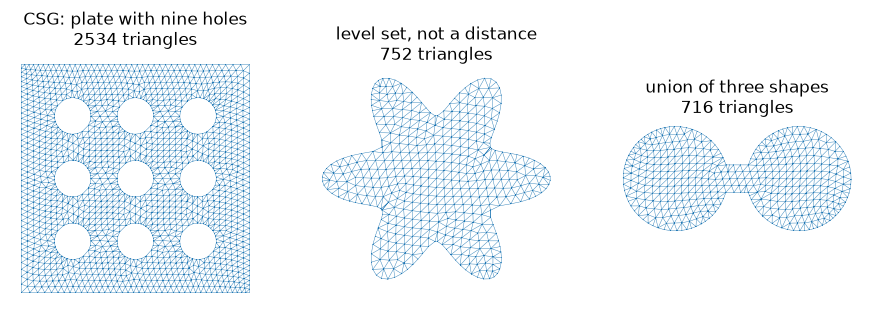

In [17]:
from physicsnemo.mesh.generate import (
    mesh_implicit_domain,
    refit_mesh_to_implicit,
    sdf_box,
    sdf_difference,
    sdf_sphere,
    sdf_union,
)

holes = [
    sdf_sphere([0.55 * i - 0.55, 0.55 * j - 0.55], 0.16)
    for i in range(3)
    for j in range(3)
]
plate = sdf_difference(sdf_box([-1, -1], [1, 1]), sdf_union(*holes))


def blob(x):
    """A level set that is not a distance function: zero on a six-lobed curve."""
    r = x.norm(dim=-1)
    theta = torch.atan2(x[..., 1], x[..., 0])
    return (r - (0.55 + 0.16 * torch.cos(6 * theta))) * 2.7


dumbbell = sdf_union(
    sdf_sphere([-0.45, 0.0], 0.38),
    sdf_sphere([0.45, 0.0], 0.38),
    sdf_box([-0.45, -0.1], [0.45, 0.1]),
)

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, (phi, bounds, title) in zip(
    axes,
    [
        (plate, ([-1, -1], [1, 1]), "CSG: plate with nine holes"),
        (blob, ([-0.85, -0.85], [0.85, 0.85]), "level set, not a distance"),
        (dumbbell, ([-1, -0.6], [1, 0.6]), "union of three shapes"),
    ],
):
    mesh = mesh_implicit_domain(phi, bounds, 0.05)
    p = mesh.points.numpy()
    ax.triplot(p[:, 0], p[:, 1], mesh.cells.numpy(), lw=0.3, color="C0")
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(f"{title}\n{mesh.n_cells} triangles")
plt.show()

### Sharp Corners Need `feature_points`

The generator projects boundary vertices onto the zero level set, but nothing
pulls a vertex into a sharp convex corner. Corners therefore come out rounded,
at the scale of `h`. The disk below has a rectangular bite, with four sharp
corners. Meshed with the defaults, its rounded corners leave a gap that trips the
coverage guard:

In [18]:
bitten = sdf_difference(sdf_sphere([0.0, 0.0], 0.7), sdf_box([0.2, -0.4], [1.0, 0.4]))
bounds = ([-1, -1], [1, 1])

try:
    mesh_implicit_domain(bitten, bounds, 0.06)
except ValueError as error:
    print(f"ValueError: {error}")

ValueError: coverage guard tripped: the zero set has a point 1.62h away from the mesh boundary (threshold 1.5h). The domain likely has features thinner than h=0.06; decrease h, or pass max_coverage_gap_h=None to accept the loss.


Pass the corners as `feature_points`. The generator pins one vertex to each of
them, so the mesh has the corners exactly. The figure zooms in on the two upper
corners of the bite (red stars). The left mesh disables the guard with
`max_coverage_gap_h=None` to show the rounded corners.

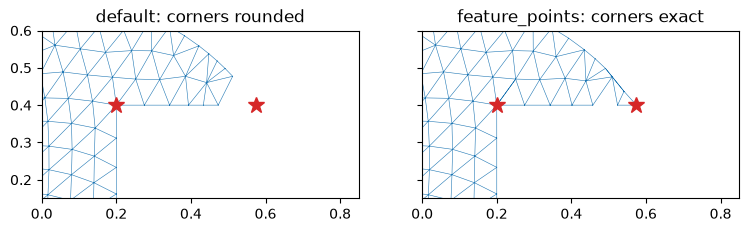

In [19]:
x_corner = math.sqrt(0.7**2 - 0.4**2)  # where the bite meets the circle
corners = torch.tensor(
    [[0.2, -0.4], [0.2, 0.4], [x_corner, 0.4], [x_corner, -0.4]], dtype=torch.float64
)

rounded = mesh_implicit_domain(bitten, bounds, 0.06, max_coverage_gap_h=None)
pinned = mesh_implicit_domain(bitten, bounds, 0.06, feature_points=corners)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), sharex=True, sharey=True)
for ax, mesh, title in [
    (axes[0], rounded, "default: corners rounded"),
    (axes[1], pinned, "feature_points: corners exact"),
]:
    p = mesh.points.numpy()
    ax.triplot(p[:, 0], p[:, 1], mesh.cells.numpy(), lw=0.4, color="C0")
    ax.plot(corners[:, 0], corners[:, 1], "*", ms=12, color="C3")
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlim(0.0, 0.85)
    ax.set_ylim(0.15, 0.6)
plt.show()

### External Flow: The Box Minus an Obstacle

Because the box clips the domain, an external-flow domain needs only the obstacle.
Pass the negated SDF of the obstacle, which is negative outside it, and let the
box faces form the farfield boundary. Here, the obstacle is a cylinder of radius
0.3 (a disk in 2D):

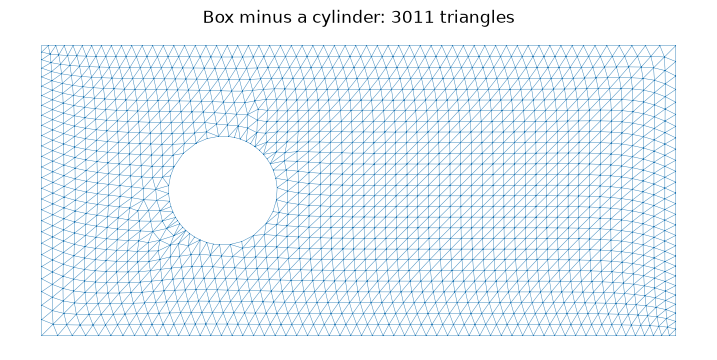

In [20]:
obstacle = sdf_sphere([0.0, 0.0], 0.3)
flow_bounds = ([-1.0, -0.8], [2.5, 0.8])
flow_mesh = mesh_implicit_domain(lambda x: -obstacle(x), flow_bounds, 0.06)

p = flow_mesh.points.numpy()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.triplot(p[:, 0], p[:, 1], flow_mesh.cells.numpy(), lw=0.3, color="C0")
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title(f"Box minus a cylinder: {flow_mesh.n_cells} triangles")
plt.show()

When you refit such a mesh with `refit_mesh_to_implicit` (Section 6), pass the
same `bounds`. The vertices on the box faces then stay on the box. As the
cylinder radius `r` grows, the fluid area shrinks at the rate of the perimeter,
$dA/dr = -2 \pi r$:

In [21]:
r = torch.tensor(0.3, dtype=torch.float64, requires_grad=True)
refit = refit_mesh_to_implicit(
    flow_mesh, lambda x: r - x.norm(dim=-1), bounds=flow_bounds
)
(grad,) = torch.autograd.grad(refit.cell_areas.sum(), r)
print(f"autograd dA/dr: {float(grad):.4f}")
print(f"exact dA/dr:    {-2 * math.pi * 0.3:.4f}")

autograd dA/dr: -1.8729
exact dA/dr:    -1.8850


### The Same Code in 3D

`mesh_implicit_domain` works in any dimension. The length of the bounds sets
the dimension. The cell below meshes a spherical shell with tetrahedra, on the
GPU when one is present. With `full_output=True`, the generator also returns
diagnostics, such as whether the boundary is closed and the fraction of sliver
cells. A sliver here is any cell with a volume-length quality below 0.2, so it
includes every kind of nearly degenerate tetrahedron, not only flat ones.

In [22]:
shell = sdf_difference(sdf_sphere([0.0] * 3, 0.8), sdf_sphere([0.0] * 3, 0.4))
shell_mesh, diagnostics = mesh_implicit_domain(
    shell, ([-1] * 3, [1] * 3), 0.09, device=device, full_output=True
)
print(shell_mesh)
print(f"closed boundary:  {diagnostics['boundary_closed_manifold']}")
print(f"sliver fraction:  {100 * diagnostics['sliver_fraction']:.1f}%")
print(f"coverage gap:     {diagnostics['coverage_gap_h']:.2f} h")

Mesh[n_manifold_dims=3, n_spatial_dims=3](n_points=3542, n_cells=15599)
closed boundary:  True
sliver fraction:  4.3%
coverage gap:     0.53 h


The volume of the shell is $\frac{4}{3}\pi(0.8^3 - 0.4^3)$. For a tetrahedral
mesh, `cell_areas` holds the volume of each cell:

In [23]:
exact_volume = 4 / 3 * math.pi * (0.8**3 - 0.4**3)
print(f"mesh volume:  {shell_mesh.cell_areas.sum():.4f}")
print(f"exact volume: {exact_volume:.4f}")

mesh volume:  1.8719
exact volume: 1.8766


The figure keeps the tetrahedra with a centroid at `x < 0` and looks at the cut,
so that you can see the cells between the two spheres. `slice_cells` keeps all
points, so `alpha_points=0.0` hides the vertex dots of the removed half.

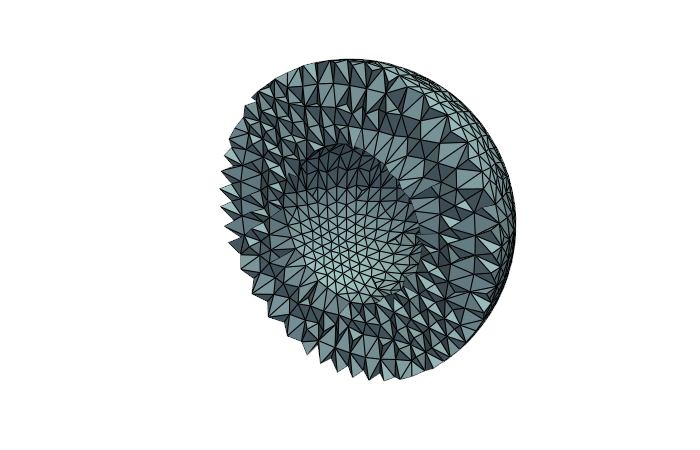

In [24]:
half_shell = shell_mesh.slice_cells(shell_mesh.cell_centroids[:, 0] < 0)
plotter = pv.Plotter()
half_shell.to("cpu").draw(backend="pyvista", ax=plotter, show=False, alpha_points=0.0)
plotter.view_yz()
plotter.camera.Azimuth(35)
plotter.camera.Elevation(20)
plotter.reset_camera()
plotter.camera.zoom(1.3)
plotter.show()

## 5. Extract an Isosurface with `marching_cubes`

Sometimes you want the surface itself, not a volume mesh: the zero level set of
a signed distance field on a grid, or an isosurface of a simulation result.
`marching_cubes` takes a 3D grid of values and returns the triangle surface where
the field crosses `threshold`. With `coords`, the vertices are in physical
coordinates instead of grid indices. The function is not differentiable.

The field below is the implicit function of a torus with radii 0.6 and 0.25:

In [25]:
from physicsnemo.mesh.generate import marching_cubes

grid = torch.linspace(-1, 1, 64)
x, y, z = torch.meshgrid(grid, grid, grid, indexing="ij")
torus_field = (torch.sqrt(x**2 + y**2) - 0.6) ** 2 + z**2 - 0.25**2

isosurface = marching_cubes(torus_field, threshold=0.0, coords=(grid, grid, grid))
print(isosurface)
print(f"surface area: {isosurface.cell_areas.sum():.4f}")
print(f"exact area:   {4 * math.pi**2 * 0.6 * 0.25:.4f}")

Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=8536, n_cells=17072)
surface area: 5.9108
exact area:   5.9218


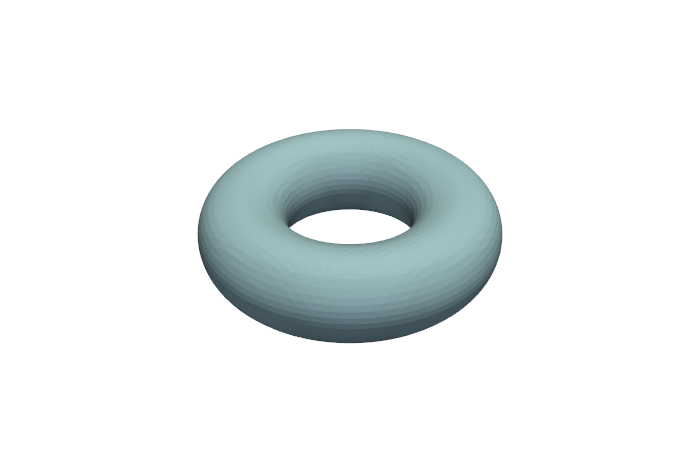

In [26]:
_ = isosurface.draw(backend="pyvista", show_edges=False, alpha_points=0.0)

## 6. Differentiate a Mesh with Respect to Its Shape

Shape optimization needs the gradient of a mesh quantity, such as a drag force
or a volume, with respect to the parameters of the shape. Meshing itself is not
differentiable, because it makes discrete choices about the connectivity.
Instead, generate the mesh once, and let `refit_mesh_to_implicit` move its
boundary vertices onto the zero level set of a new function. The connectivity
stays the same, and the new vertex positions are differentiable with respect to
the parameters inside the function.

The cell below refits a disk of radius 0.7 to nearby radii `r`, and compares the
derivative of the area from autograd with the exact value, $dA/dr = 2 \pi r$
(the perimeter):

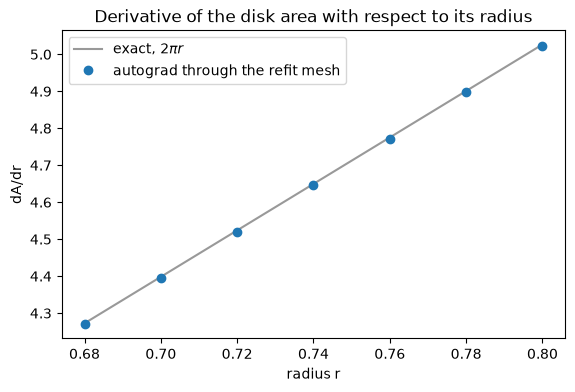

In [27]:
base = mesh_implicit_domain(sdf_sphere([0.0, 0.0], 0.7), ([-1, -1], [1, 1]), 0.06)

radii = torch.linspace(0.68, 0.8, 7, dtype=torch.float64)
dA_dr = []
for r0 in radii:
    r = r0.clone().requires_grad_(True)
    refit = refit_mesh_to_implicit(base, lambda x, r=r: x.norm(dim=-1) - r)
    (grad,) = torch.autograd.grad(refit.cell_areas.sum(), r)
    dA_dr.append(float(grad))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(radii, 2 * math.pi * radii, "-", color="0.6", label=r"exact, $2 \pi r$")
ax.plot(radii, dA_dr, "o", color="C0", label="autograd through the refit mesh")
ax.set_xlabel("radius r")
ax.set_ylabel("dA/dr")
ax.legend()
ax.set_title("Derivative of the disk area with respect to its radius")
plt.show()

Refitting works for small changes of shape. Only the boundary vertices move, so
a large change can invert the cells next to the boundary. Shrinking this disk to
`r = 0.65` already does. `refit_mesh_to_implicit` then warns with a
`UserWarning`, and the gradients are wrong. Generate a new mesh in that case.

## Summary

This tutorial covered the following points:

- `physicsnemo.mesh.primitives` builds example meshes in seven families. Each
  module has a `load` function, and most take size, resolution, and `device`
  arguments.
- Procedural primitives are seeded, so tests that use them are reproducible.
- `fill_interior` fills closed 2D boundary loops with triangles. It keeps the
  input vertices exactly, guarantees a minimum angle when the input corners are
  at least about 60 degrees, and records provenance.
- `mesh_implicit_domain` meshes `{phi < 0}` inside a box, in any dimension. For
  an external flow, pass the negated SDF of the obstacle. A coverage guard
  raises an error when the mesh misses a feature, and `feature_points` keeps
  sharp corners.
- `marching_cubes` extracts an isosurface from a 3D grid of values.
- `refit_mesh_to_implicit` gives gradients of mesh quantities with respect to
  shape parameters, at fixed connectivity.

## Next Steps

Continue with the following resources:

- **Next:** [Tutorial 4: Mesh Operations](tutorial_4_operations.ipynb)
  transforms, subdivides, slices, and merges meshes, and extracts their
  boundaries and edge graphs.
- [Tutorial 7: Quality, Validation, and Repair](tutorial_7_quality_repair.ipynb)
  explains the quality metrics used here.
- API Reference: [primitives](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/primitives.html),
  [generate](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/generate.html),
  and [tessellation](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/tessellation.html).
- User Guide: [PhysicsNeMo-Mesh](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh.html).